In [167]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import roc_curve, auc, confusion_matrix
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import label_binarize


In [24]:
metadata = pd.read_csv('metadata.csv')

In [25]:
dataset = pd.read_csv('final_dataset.csv')
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 821 entries, 0 to 820
Data columns (total 52 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   zero_crossing_rate   821 non-null    float64
 1   energy               821 non-null    float64
 2   spectral_centroid    821 non-null    float64
 3   spectral_bandwidth   821 non-null    float64
 4   log_mel_1            821 non-null    float64
 5   log_mel_2            821 non-null    float64
 6   log_mel_3            821 non-null    float64
 7   log_mel_4            821 non-null    float64
 8   log_mel_5            821 non-null    float64
 9   log_mel_6            821 non-null    float64
 10  log_mel_7            821 non-null    float64
 11  log_mel_8            821 non-null    float64
 12  log_mel_9            821 non-null    float64
 13  log_mel_10           821 non-null    float64
 14  log_mel_11           821 non-null    float64
 15  log_mel_12           821 non-null    flo

# Gender Classification

In [26]:
dataset['gender'].value_counts()

gender
male      631
female    190
Name: count, dtype: int64

In [27]:
dataset['gender'] = dataset['gender'].apply(lambda x: 1 if x == 'male' else 0)

In [28]:
gender_dataset = dataset.drop(columns=['has_intro', 'student_id', 'question_number', 'file_name'], inplace=False)

In [29]:
gender_dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 821 entries, 0 to 820
Data columns (total 48 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   zero_crossing_rate   821 non-null    float64
 1   energy               821 non-null    float64
 2   spectral_centroid    821 non-null    float64
 3   spectral_bandwidth   821 non-null    float64
 4   log_mel_1            821 non-null    float64
 5   log_mel_2            821 non-null    float64
 6   log_mel_3            821 non-null    float64
 7   log_mel_4            821 non-null    float64
 8   log_mel_5            821 non-null    float64
 9   log_mel_6            821 non-null    float64
 10  log_mel_7            821 non-null    float64
 11  log_mel_8            821 non-null    float64
 12  log_mel_9            821 non-null    float64
 13  log_mel_10           821 non-null    float64
 14  log_mel_11           821 non-null    float64
 15  log_mel_12           821 non-null    flo

In [30]:
# Select 190 samples each from males and females
male_samples = gender_dataset[gender_dataset['gender'] == 1].sample(n=190, random_state=42)
female_samples = gender_dataset[gender_dataset['gender'] == 0].sample(n=190, random_state=42)

balanced_dataset = pd.concat([male_samples, female_samples])

train_set, test_set = train_test_split(balanced_dataset, test_size=0.25, random_state=42, stratify=balanced_dataset['gender'])

# Display the shapes of the resulting datasets
print(f"Training set shape: {train_set.shape}")
print(f"Testing set shape: {test_set.shape}")

Training set shape: (285, 48)
Testing set shape: (95, 48)


In [31]:
def get_corr(data):
    num_cols = data.select_dtypes(include=['int64', 'float64']).columns   
    corr_matrix = data[num_cols].corr()
    upper_triangle = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
    high_corr_features = [(column, upper_triangle[column].idxmax(), upper_triangle[column].max()) for column in upper_triangle.columns if any(upper_triangle[column] > 0.9)]
    for feature1, feature2, corr_value in high_corr_features:
        print(f"{feature1} and {feature2} have a correlation of {corr_value}")
    return corr_matrix

spectral_centroid and zero_crossing_rate have a correlation of 0.9903635146873123
log_mel_5 and log_mel_4 have a correlation of 0.9460780907280261
log_mel_6 and log_mel_5 have a correlation of 0.9659725629604006
log_mel_7 and log_mel_6 have a correlation of 0.960022540388093
log_mel_8 and log_mel_7 have a correlation of 0.9538645703183916
log_mel_9 and log_mel_8 have a correlation of 0.9228917991222666
log_mel_10 and log_mel_9 have a correlation of 0.910924004730554
log_mel_12 and log_mel_11 have a correlation of 0.901269345264183
log_mel_17 and log_mel_16 have a correlation of 0.9337996433657169
log_mel_18 and log_mel_17 have a correlation of 0.9393516028918286
log_mel_19 and log_mel_18 have a correlation of 0.933225958834208
log_mel_20 and log_mel_19 have a correlation of 0.9417058169778803
log_mel_21 and log_mel_20 have a correlation of 0.9734443556833696
log_mel_22 and log_mel_21 have a correlation of 0.9671741526035247
mfcc_2 and log_mel_3 have a correlation of 0.900788847611454


<Axes: >

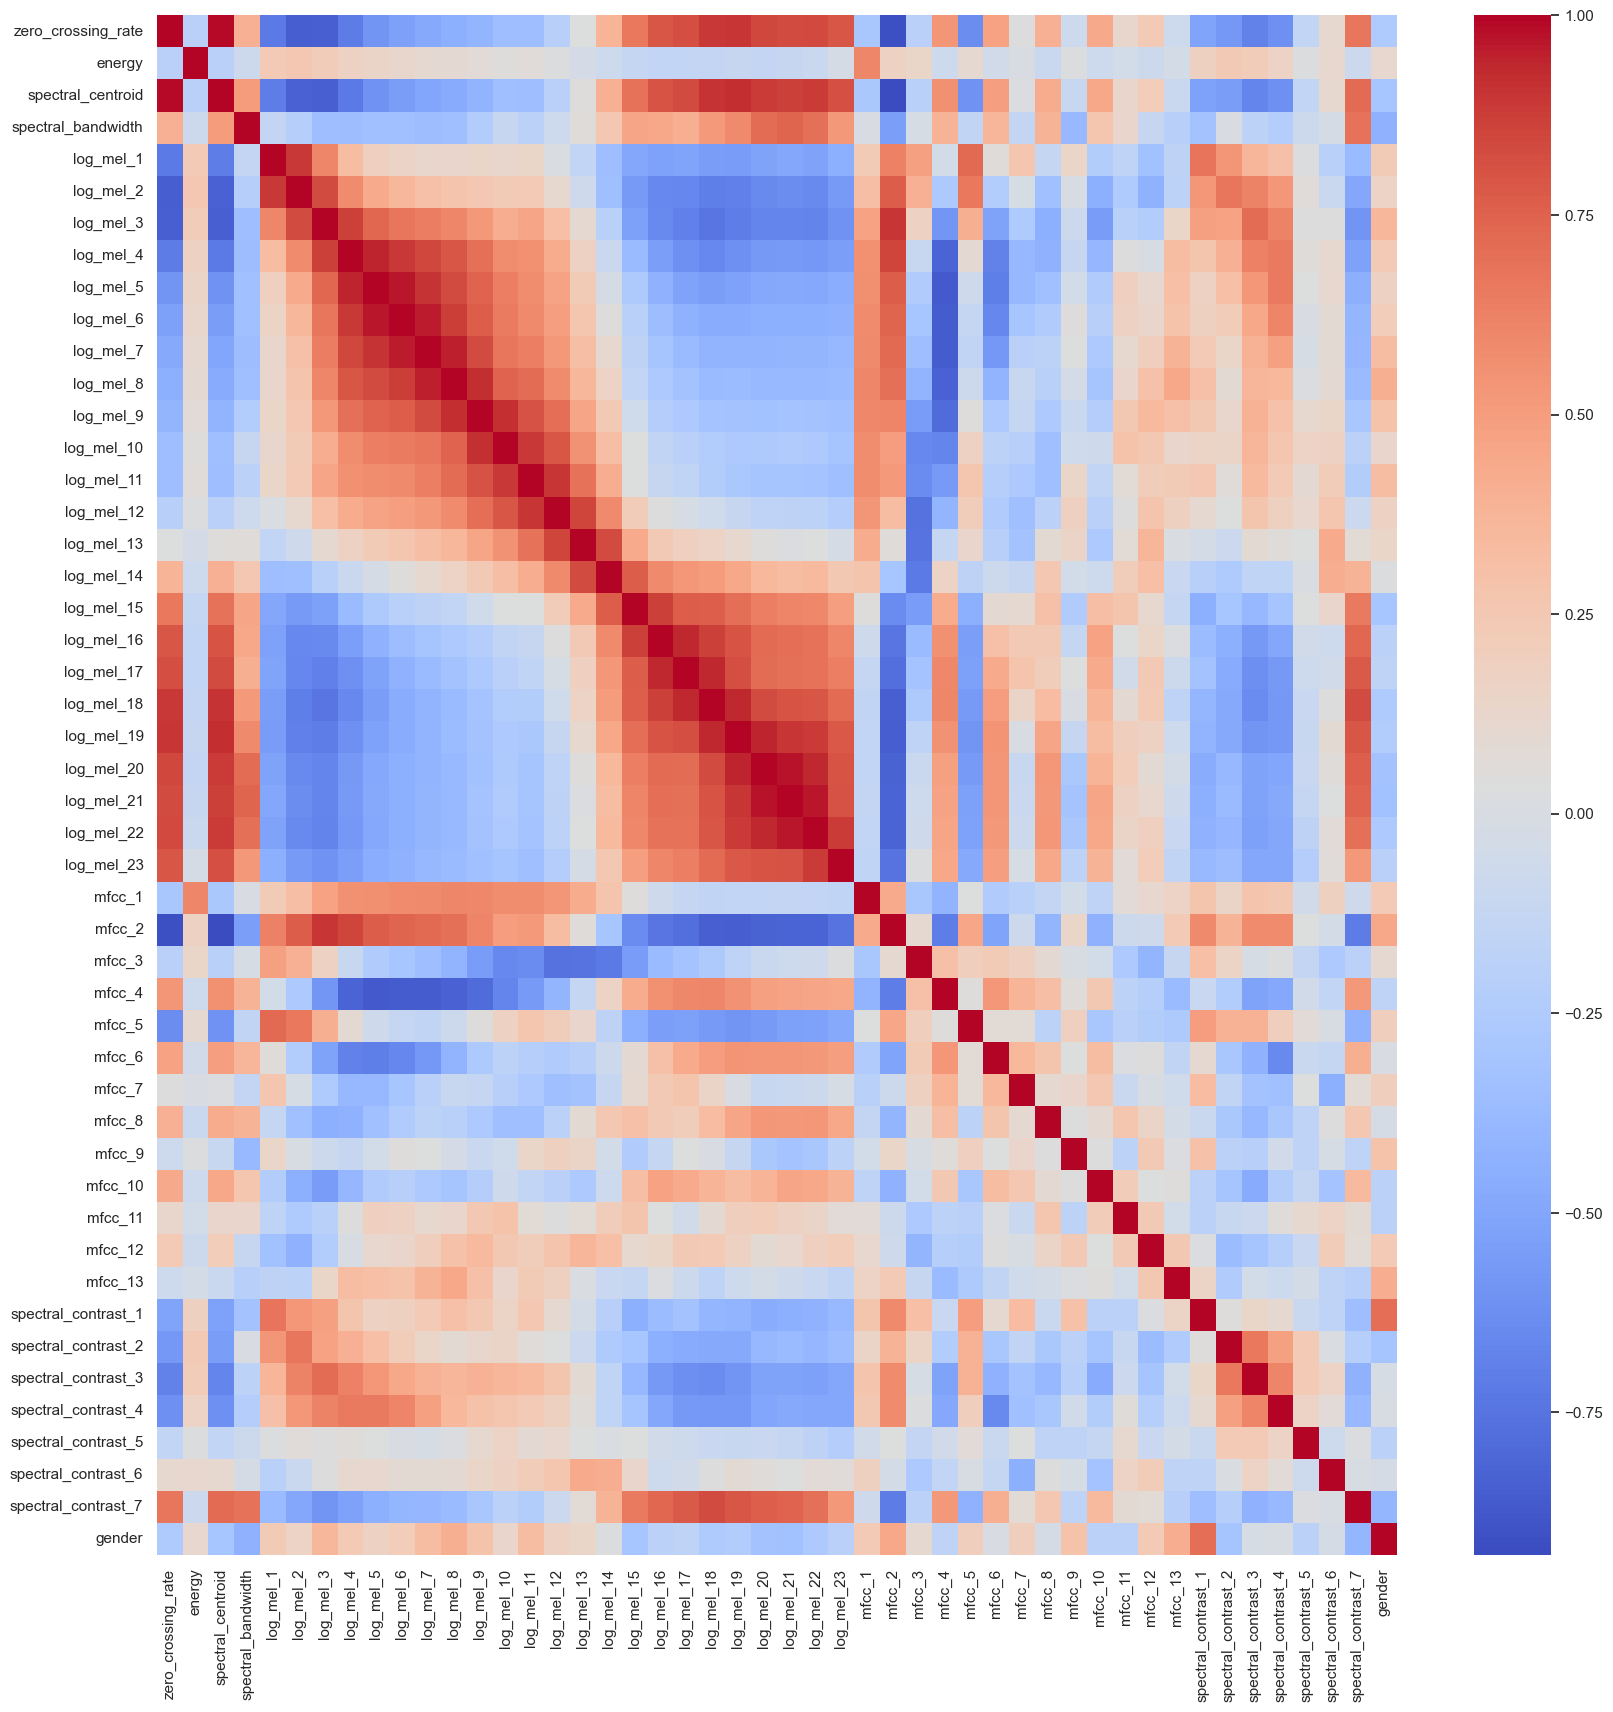

In [32]:
corr_matrix = get_corr(balanced_dataset)
sns.set(rc={'figure.figsize':(20,20)})
sns.heatmap(corr_matrix, cmap="coolwarm", annot=False)


In [33]:
df = balanced_dataset.copy()

log_mel_features = [col for col in df.columns if "log_mel" in col]
log_mel_data = df[log_mel_features]

scaler = StandardScaler()
log_mel_scaled = scaler.fit_transform(log_mel_data)

pca = PCA(n_components=0.95)
log_mel_pca = pca.fit_transform(log_mel_scaled)

pca_columns = [f"log_mel_pca_{i}" for i in range(log_mel_pca.shape[1])]
df_pca = pd.DataFrame(log_mel_pca, columns=pca_columns)

df = df.drop(columns=log_mel_features)
df.reset_index(drop=True, inplace=True)
df_pca.reset_index(drop=True, inplace=True)
df = pd.concat([df, df_pca], axis=1)

print(f"Original log-mel features: {len(log_mel_features)}, Reduced to: {len(pca_columns)}")


Original log-mel features: 23, Reduced to: 8


In [34]:
corr_matrix = get_corr(df)

spectral_centroid and zero_crossing_rate have a correlation of 0.9903635146873123
log_mel_pca_0 and mfcc_2 have a correlation of 0.9786177248941503


In [35]:
print(df['spectral_centroid'].corr(df['gender']))
print(df['zero_crossing_rate'].corr(df['gender']))

print(df['log_mel_pca_0'].corr(df['gender']))
print(df['mfcc_2'].corr(df['gender']))

-0.29786641424890303
-0.25609009781171366
0.33240019625432754
0.44319399123839637


In [36]:
df.drop(columns=['zero_crossing_rate', 'log_mel_pca_0'], inplace=True)

In [37]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 380 entries, 0 to 379
Data columns (total 31 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   energy               380 non-null    float64
 1   spectral_centroid    380 non-null    float64
 2   spectral_bandwidth   380 non-null    float64
 3   mfcc_1               380 non-null    float64
 4   mfcc_2               380 non-null    float64
 5   mfcc_3               380 non-null    float64
 6   mfcc_4               380 non-null    float64
 7   mfcc_5               380 non-null    float64
 8   mfcc_6               380 non-null    float64
 9   mfcc_7               380 non-null    float64
 10  mfcc_8               380 non-null    float64
 11  mfcc_9               380 non-null    float64
 12  mfcc_10              380 non-null    float64
 13  mfcc_11              380 non-null    float64
 14  mfcc_12              380 non-null    float64
 15  mfcc_13              380 non-null    flo

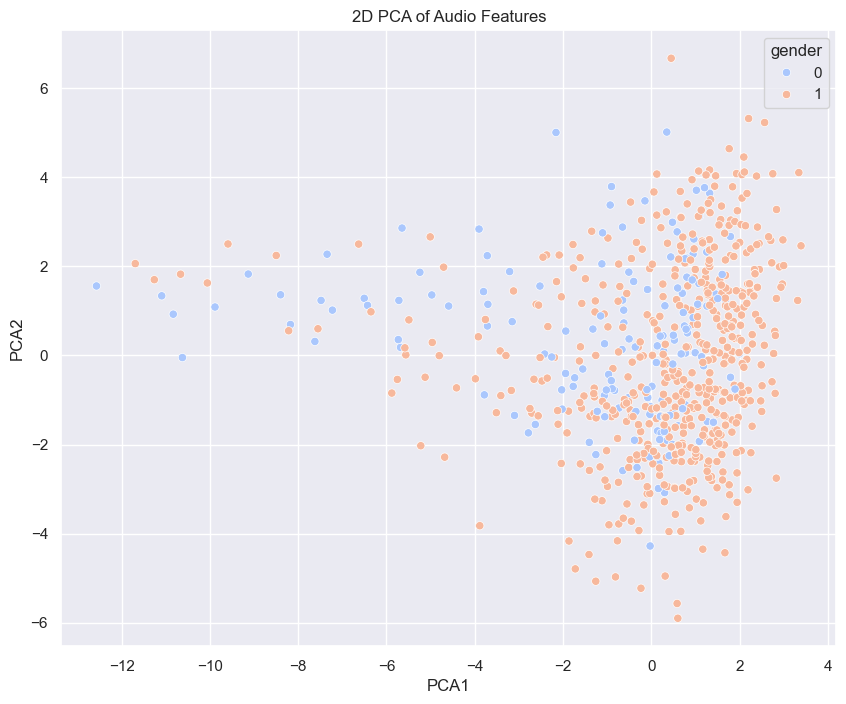

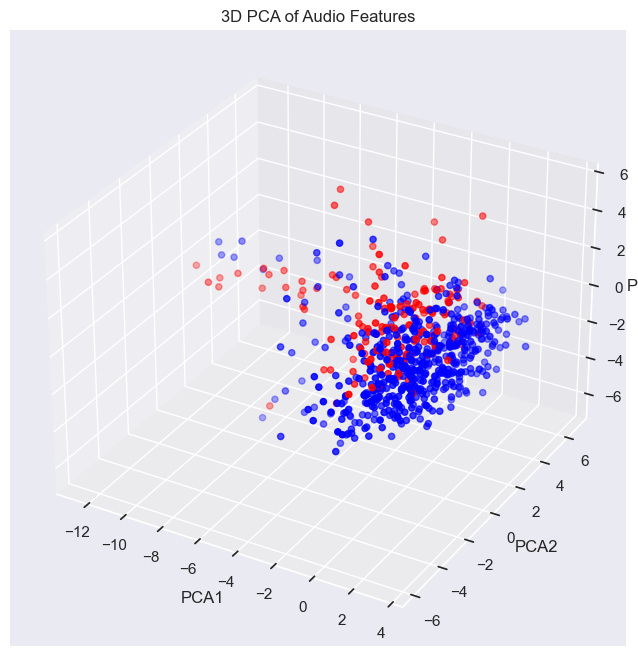

In [109]:
def plot_PCA(df, target, n_components):
    scaler = StandardScaler()
    scaled_features = scaler.fit_transform(df.drop(columns=[target]))

    pca = PCA(n_components=n_components)
    pca_result = pca.fit_transform(scaled_features)

    if n_components == 2:
        df['PCA1'] = pca_result[:, 0]
        df['PCA2'] = pca_result[:, 1]

        plt.figure(figsize=(10, 8))
        sns.scatterplot(x='PCA1', y='PCA2', hue=target, data=df, palette='coolwarm')
        plt.title('2D PCA of Audio Features')
        plt.show()

        df.drop(columns=['PCA1', 'PCA2'], inplace=True)

    elif n_components == 3:
        df['PCA1'] = pca_result[:, 0]
        df['PCA2'] = pca_result[:, 1]
        df['PCA3'] = pca_result[:, 2]

        fig = plt.figure(figsize=(10, 8))
        ax = fig.add_subplot(111, projection='3d')
        colors = {1: 'blue', 0: 'red', 2: 'green', 3: 'yellow', 4: 'purple', 5: 'orange'}
        ax.scatter(df['PCA1'], df['PCA2'], df['PCA3'], c=df[target].apply(lambda x: colors[x]))
        ax.set_xlabel('PCA1')
        ax.set_ylabel('PCA2')
        ax.set_zlabel('PCA3')
        plt.title('3D PCA of Audio Features')
        plt.show()

        df.drop(columns=['PCA1', 'PCA2', 'PCA3'], inplace=True)


plot_PCA(df, 'gender', 2)
plot_PCA(df, 'gender', 3)

# Normalization

In [42]:
X = df.drop(columns=["gender"])
y = df["gender"] 

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=95/380, random_state=42, stratify=y)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Training Models

In [43]:
models = {
    "SVM": SVC(kernel="rbf", probability=True, random_state=42),
    "Logistic Regression": LogisticRegression(random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=5)
}

predictions = {
    "MLP": [],
    "SVM": [],
    "Logistic Regression": [],
    "KNN": [],
}

probabilities = {
    "MLP": [],
    "SVM": [],
    "Logistic Regression": [],
    "KNN": [],
}

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    predictions[name] = y_pred
    probabilities[name] = y_prob
    accuracy = accuracy_score(y_test, y_pred)
    print(f" {name} Accuracy: {accuracy:.4f}")
    # print(classification_report(y_test, y_pred))


 SVM Accuracy: 0.9684
 Logistic Regression Accuracy: 0.9474
 KNN Accuracy: 0.9158


In [ ]:
MLP = MLPClassifier(
    hidden_layer_sizes=(128, 64, 32),  
    activation="relu",               
    solver="adam",                    
    alpha=0.02,                       
    batch_size=16,                      
    learning_rate="adaptive",           
    max_iter=1000,                     
    random_state=42
)

MLP.fit(X_train, y_train)

y_pred_optimized = MLP.predict(X_test)
y_proba = MLP.predict_proba(X_test)[:, 1]
predictions["MLP"] = y_pred_optimized
probabilities["MLP"] = y_proba
accuracy_optimized = accuracy_score(y_test, y_pred_optimized)


print(f"MLP Accuracy: {accuracy_optimized:.4f}")
print(classification_report(y_test, y_pred_optimized))


MLP Accuracy: 0.9684
              precision    recall  f1-score   support

           0       0.94      1.00      0.97        48
           1       1.00      0.94      0.97        47

    accuracy                           0.97        95
   macro avg       0.97      0.97      0.97        95
weighted avg       0.97      0.97      0.97        95



In [45]:
def ROC_curve(y_true, y_prob, model_name):
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    roc_auc = auc(fpr, tpr)

    plt.figure(figsize=(8, 6))
    plt.plot(fpr, tpr, color='blue', lw=2, label=f'ROC curve (AUC = {roc_auc:.2f})')
    plt.plot([0, 1], [0, 1], color='gray', linestyle='--')  # Diagonal line
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title(model_name +' ROC Curve')
    plt.legend(loc="lower right")
    plt.grid()
    plt.show()

In [46]:
def confusion_matrix_plot(y_true, y_pred, model_name):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["Male", "Female"], yticklabels=["Male", "Female"])
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title(model_name+ " Confusion Matrix")
    plt.show()

# MLP model

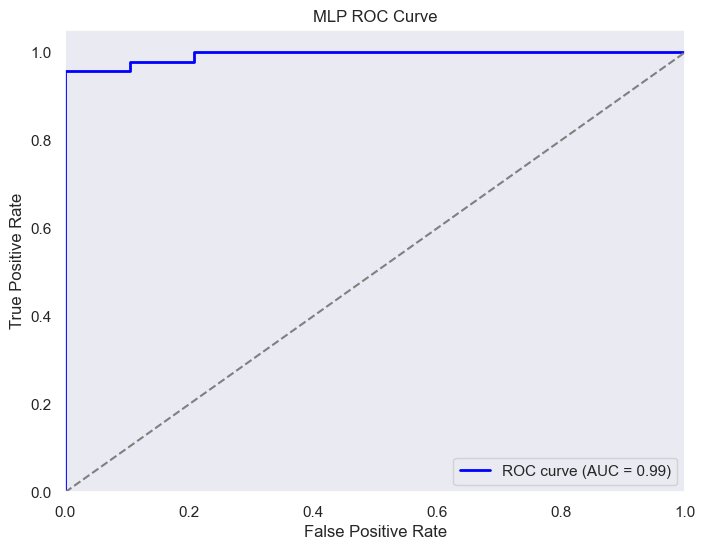

In [47]:
y_pred = predictions["MLP"]
y_proba = probabilities["MLP"]

ROC_curve(y_test, y_proba, "MLP")

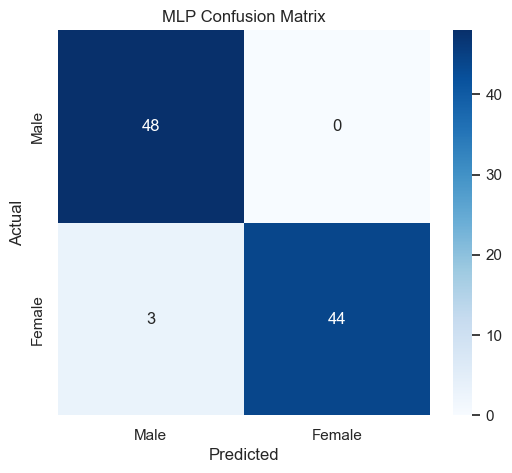

In [48]:
confusion_matrix_plot(y_test, y_pred, "MLP")

# SVM

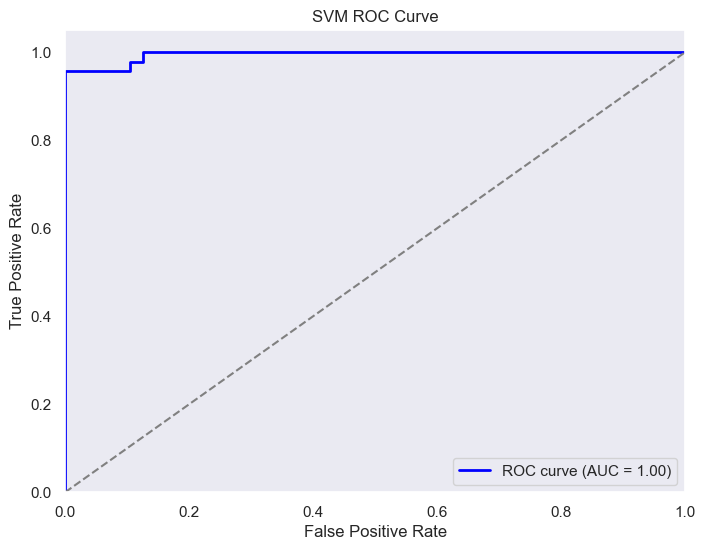

In [49]:
y_pred = predictions["SVM"]
y_proba = probabilities["SVM"]

ROC_curve(y_test, y_proba, "SVM")

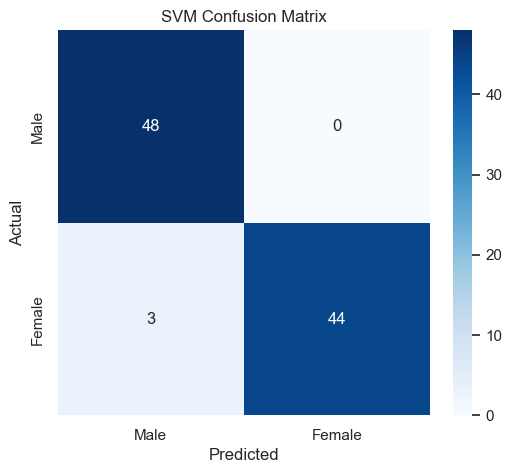

In [50]:
confusion_matrix_plot(y_test, y_pred, "SVM")

# Logistic Regression

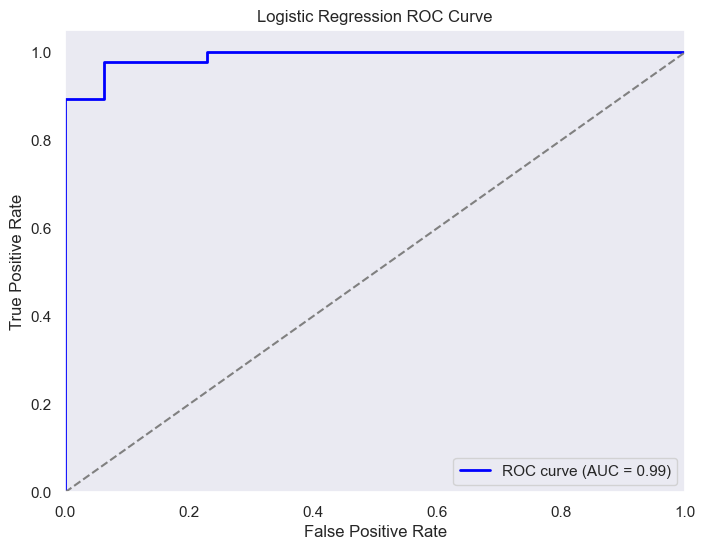

In [51]:
y_pred = predictions["Logistic Regression"]
y_proba = probabilities["Logistic Regression"]

ROC_curve(y_test, y_proba, "Logistic Regression")

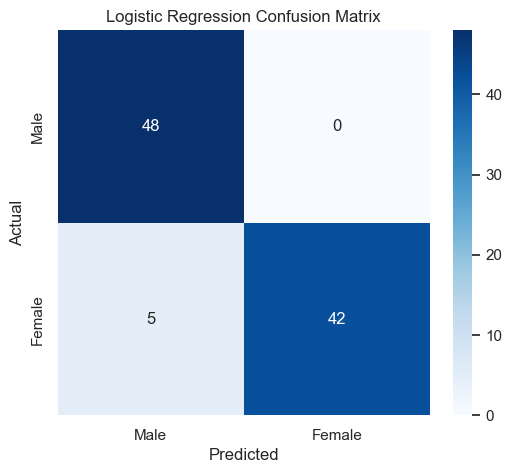

In [52]:
confusion_matrix_plot(y_test, y_pred, "Logistic Regression")    

# KNN

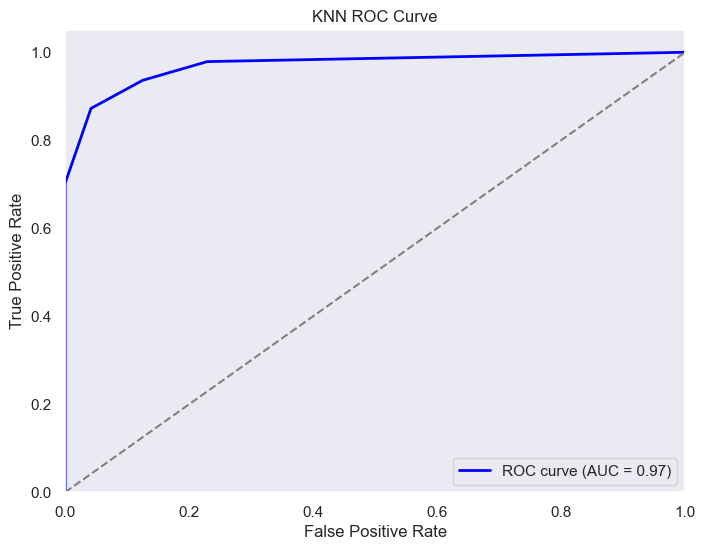

In [53]:
y_pred = predictions["KNN"]
y_proba = probabilities["KNN"]

ROC_curve(y_test, y_proba, "KNN")

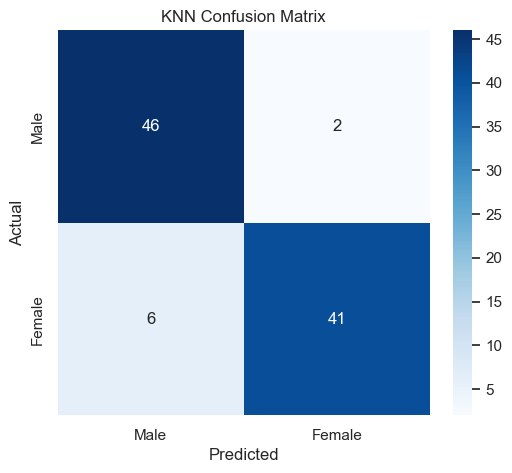

In [54]:
confusion_matrix_plot(y_test, y_pred, "KNN")

# Identity Recognition (Closed-Set Authentication)

In [55]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 821 entries, 0 to 820
Data columns (total 52 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   zero_crossing_rate   821 non-null    float64
 1   energy               821 non-null    float64
 2   spectral_centroid    821 non-null    float64
 3   spectral_bandwidth   821 non-null    float64
 4   log_mel_1            821 non-null    float64
 5   log_mel_2            821 non-null    float64
 6   log_mel_3            821 non-null    float64
 7   log_mel_4            821 non-null    float64
 8   log_mel_5            821 non-null    float64
 9   log_mel_6            821 non-null    float64
 10  log_mel_7            821 non-null    float64
 11  log_mel_8            821 non-null    float64
 12  log_mel_9            821 non-null    float64
 13  log_mel_10           821 non-null    float64
 14  log_mel_11           821 non-null    float64
 15  log_mel_12           821 non-null    flo

In [62]:
dataset['student_id'].value_counts().to_list()

[12,
 11,
 10,
 9,
 9,
 9,
 9,
 8,
 8,
 8,
 7,
 7,
 7,
 7,
 7,
 7,
 7,
 7,
 7,
 7,
 7,
 7,
 7,
 7,
 7,
 7,
 7,
 7,
 7,
 7,
 7,
 7,
 7,
 7,
 7,
 7,
 7,
 7,
 7,
 7,
 7,
 7,
 7,
 7,
 7,
 7,
 7,
 7,
 7,
 7,
 7,
 7,
 7,
 7,
 7,
 7,
 7,
 7,
 7,
 7,
 7,
 7,
 7,
 7,
 7,
 7,
 7,
 7,
 7,
 7,
 7,
 7,
 7,
 7,
 7,
 7,
 7,
 7,
 7,
 7,
 7,
 7,
 7,
 7,
 7,
 7,
 7,
 7,
 7,
 7,
 7,
 7,
 7,
 7,
 7,
 7,
 7,
 7,
 7,
 6,
 6,
 6,
 6,
 6,
 6,
 6,
 6,
 6,
 6,
 6,
 6,
 6,
 6,
 6,
 5,
 5,
 4,
 1]

In [66]:
# Filter out student_ids with less than 7 occurrences
student_counts = dataset['student_id'].value_counts()
students_to_keep = student_counts[student_counts >= 7].index

filtered_dataset = dataset[dataset['student_id'].isin(students_to_keep)]

# Ensure no student_id has more than 7 occurrences
for student_id in students_to_keep:
    student_data = filtered_dataset[filtered_dataset['student_id'] == student_id]
    if len(student_data) > 7:
        filtered_dataset = filtered_dataset.drop(student_data.index[7:])

print(f"Filtered dataset shape: {filtered_dataset.shape}")

Filtered dataset shape: (693, 52)


In [68]:
filtered_dataset.drop(columns=['has_intro', 'question_number', 'file_name'], inplace=True)
filtered_dataset.info()

<class 'pandas.core.frame.DataFrame'>
Index: 693 entries, 0 to 820
Data columns (total 49 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   zero_crossing_rate   693 non-null    float64
 1   energy               693 non-null    float64
 2   spectral_centroid    693 non-null    float64
 3   spectral_bandwidth   693 non-null    float64
 4   log_mel_1            693 non-null    float64
 5   log_mel_2            693 non-null    float64
 6   log_mel_3            693 non-null    float64
 7   log_mel_4            693 non-null    float64
 8   log_mel_5            693 non-null    float64
 9   log_mel_6            693 non-null    float64
 10  log_mel_7            693 non-null    float64
 11  log_mel_8            693 non-null    float64
 12  log_mel_9            693 non-null    float64
 13  log_mel_10           693 non-null    float64
 14  log_mel_11           693 non-null    float64
 15  log_mel_12           693 non-null    float64


In [69]:
get_corr(filtered_dataset)

spectral_centroid and zero_crossing_rate have a correlation of 0.9873495761588788
log_mel_5 and log_mel_4 have a correlation of 0.9485918635416437
log_mel_6 and log_mel_5 have a correlation of 0.9693198144153269
log_mel_7 and log_mel_6 have a correlation of 0.9601556632596159
log_mel_8 and log_mel_7 have a correlation of 0.9438420228809957
log_mel_10 and log_mel_9 have a correlation of 0.9004813474700537
log_mel_12 and log_mel_11 have a correlation of 0.9021097376446617
log_mel_17 and log_mel_16 have a correlation of 0.93673263967446
log_mel_18 and log_mel_17 have a correlation of 0.9366950640658995
log_mel_19 and log_mel_18 have a correlation of 0.910919525407038
log_mel_20 and log_mel_19 have a correlation of 0.939390615566279
log_mel_21 and log_mel_20 have a correlation of 0.9623615317522365
log_mel_22 and log_mel_21 have a correlation of 0.9568982223551553


,zero_crossing_rate,energy,spectral_centroid,spectral_bandwidth,log_mel_1,log_mel_2,log_mel_3,log_mel_4,log_mel_5,log_mel_6,...,mfcc_12,mfcc_13,spectral_contrast_1,spectral_contrast_2,spectral_contrast_3,spectral_contrast_4,spectral_contrast_5,spectral_contrast_6,spectral_contrast_7,gender
zero_crossing_rate,1.000000,-0.184005,0.987350,0.410046,-0.689459,-0.829419,-0.839014,-0.658125,-0.541572,-0.491747,...,0.164791,-0.065028,-0.544883,-0.521502,-0.605572,-0.508826,-0.019467,0.048908,0.671605,-0.257694
energy,-0.184005,1.000000,-0.180260,-0.070923,0.147523,0.183014,0.154483,0.110205,0.066297,0.041899,...,-0.112096,-0.024958,0.132152,0.246002,0.188057,0.196503,0.027853,0.043926,-0.107801,0.042505
spectral_centroid,0.987350,-0.180260,1.000000,0.528849,-0.665935,-0.807007,-0.833232,-0.660948,-0.549792,-0.504773,...,0.155561,-0.086160,-0.552216,-0.478535,-0.575217,-0.502410,-0.025405,0.057057,0.720194,-0.295242
spectral_bandwidth,0.410046,-0.070923,0.528849,1.000000,-0.119186,-0.199106,-0.342742,-0.333098,-0.315112,-0.321401,...,-0.060412,-0.202781,-0.272512,0.038389,-0.119403,-0.175204,-0.054157,-0.020873,0.693151,-0.383285
log_mel_1,-0.689459,0.147523,-0.665935,-0.119186,1.000000,0.882674,0.552740,0.203025,0.081965,0.078913,...,-0.322222,-0.252618,0.743512,0.445711,0.263397,0.205343,-0.088895,-0.125658,-0.339194,0.201414
log_mel_2,-0.829419,0.183014,-0.807007,-0.199106,0.882674,1.000000,0.803462,0.458691,0.311288,0.282001,...,-0.398079,-0.253509,0.604562,0.603432,0.525612,0.413554,-0.058273,-0.024704,-0.453721,0.147884
log_mel_3,-0.839014,0.154483,-0.833232,-0.342742,0.552740,0.803462,1.000000,0.841145,0.700577,0.657553,...,-0.180115,0.125164,0.483792,0.463110,0.621635,0.545977,-0.040716,0.107459,-0.595113,0.311925
log_mel_4,-0.658125,0.110205,-0.660948,-0.333098,0.203025,0.458691,0.841145,1.000000,0.948592,0.896391,...,0.123880,0.402267,0.218214,0.363937,0.505623,0.558033,0.006399,0.178836,-0.527434,0.186786
log_mel_5,-0.541572,0.066297,-0.549792,-0.315112,0.081965,0.311288,0.700577,0.948592,1.000000,0.969320,...,0.219673,0.414445,0.115275,0.278041,0.392125,0.548507,0.006297,0.169693,-0.460028,0.126141
log_mel_6,-0.491747,0.041899,-0.504773,-0.321401,0.078913,0.282001,0.657553,0.896391,0.969320,1.000000,...,0.189624,0.375536,0.139116,0.203979,0.312325,0.511890,-0.012670,0.142452,-0.424129,0.165518


In [70]:
df = filtered_dataset.copy()

log_mel_features = [col for col in df.columns if "log_mel" in col]
log_mel_data = df[log_mel_features]

scaler = StandardScaler()
log_mel_scaled = scaler.fit_transform(log_mel_data)

pca = PCA(n_components=0.95)
log_mel_pca = pca.fit_transform(log_mel_scaled)

pca_columns = [f"log_mel_pca_{i}" for i in range(log_mel_pca.shape[1])]
df_pca = pd.DataFrame(log_mel_pca, columns=pca_columns)

df = df.drop(columns=log_mel_features)
df.reset_index(drop=True, inplace=True)
df_pca.reset_index(drop=True, inplace=True)
df = pd.concat([df, df_pca], axis=1)

print(f"Original log-mel features: {len(log_mel_features)}, Reduced to: {len(pca_columns)}")

Original log-mel features: 23, Reduced to: 8


In [71]:
get_corr(df)

spectral_centroid and zero_crossing_rate have a correlation of 0.9873495761588788
log_mel_pca_0 and spectral_centroid have a correlation of 0.9290487323472196


,zero_crossing_rate,energy,spectral_centroid,spectral_bandwidth,mfcc_1,mfcc_2,mfcc_3,mfcc_4,mfcc_5,mfcc_6,...,spectral_contrast_7,gender,log_mel_pca_0,log_mel_pca_1,log_mel_pca_2,log_mel_pca_3,log_mel_pca_4,log_mel_pca_5,log_mel_pca_6,log_mel_pca_7
zero_crossing_rate,1.000000,-0.184005,0.987350,0.410046,-0.305284,-0.899572,-0.349941,0.518216,-0.557813,0.286725,...,0.671605,-0.257694,9.062173e-01,2.423735e-01,-1.023387e-01,-1.715026e-01,5.395498e-02,-1.187549e-03,-1.504933e-02,-4.160593e-02
energy,-0.184005,1.000000,-0.180260,-0.070923,0.446443,0.112605,0.150853,-0.040435,0.079977,-0.066979,...,-0.107801,0.042505,-1.293608e-01,-1.173820e-01,-2.815628e-02,7.629116e-02,-6.136688e-02,3.908003e-02,9.273255e-02,-7.286269e-02
spectral_centroid,0.987350,-0.180260,1.000000,0.528849,-0.266400,-0.921335,-0.351029,0.532828,-0.534459,0.315521,...,0.720194,-0.295242,9.290487e-01,2.646865e-01,-1.103584e-01,-8.883806e-02,6.144724e-02,1.383958e-02,-2.509642e-02,-2.635786e-02
spectral_bandwidth,0.410046,-0.070923,0.528849,1.000000,0.055896,-0.550122,-0.061961,0.361525,-0.148437,0.353326,...,0.693151,-0.383285,5.761029e-01,1.701933e-01,-1.863322e-01,4.843242e-01,3.152023e-02,1.692467e-02,-1.445877e-01,8.540920e-02
mfcc_1,-0.305284,0.446443,-0.266400,0.055896,1.000000,0.461532,-0.336109,-0.517104,0.003061,-0.283311,...,-0.118362,0.202606,-4.336593e-01,5.955972e-01,-6.378600e-02,1.914347e-01,-1.084693e-01,-2.999840e-02,-3.227365e-02,-4.666715e-03
mfcc_2,-0.899572,0.112605,-0.921335,-0.550122,0.461532,1.000000,0.210009,-0.693801,0.370297,-0.385605,...,-0.722381,0.401663,-9.764726e-01,-5.821150e-04,-1.447112e-02,8.475120e-02,-1.010025e-01,-3.385465e-02,7.376207e-03,-9.269853e-03
mfcc_3,-0.349941,0.150853,-0.351029,-0.061961,-0.336109,0.210009,1.000000,0.240098,0.223454,0.238818,...,-0.267422,0.101216,-1.386798e-01,-8.399218e-01,-2.860660e-01,3.405033e-01,-1.659456e-01,2.604934e-02,-1.529994e-03,-5.854266e-02
mfcc_4,0.518216,-0.040435,0.532828,0.361525,-0.517104,-0.693801,0.240098,1.000000,0.140493,0.466244,...,0.533349,-0.109110,7.617413e-01,-3.857245e-01,3.717993e-01,1.875471e-01,-2.720645e-01,-1.165171e-02,1.515489e-03,-9.720555e-03
mfcc_5,-0.557813,0.079977,-0.534459,-0.148437,0.003061,0.370297,0.223454,0.140493,1.000000,0.283335,...,-0.319076,0.206481,-3.625324e-01,-3.008772e-01,7.002486e-01,4.506267e-01,1.926481e-01,7.555558e-02,7.626793e-02,6.543829e-02
mfcc_6,0.286725,-0.066979,0.315521,0.353326,-0.283311,-0.385605,0.238818,0.466244,0.283335,1.000000,...,0.312108,-0.026267,4.311119e-01,-2.458335e-01,1.477743e-01,5.021910e-01,4.343043e-01,-4.242615e-01,-6.467810e-02,-5.078424e-02


In [72]:
df.drop(columns=['zero_crossing_rate', 'log_mel_pca_0'], inplace=True)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 693 entries, 0 to 692
Data columns (total 32 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   energy               693 non-null    float64
 1   spectral_centroid    693 non-null    float64
 2   spectral_bandwidth   693 non-null    float64
 3   mfcc_1               693 non-null    float64
 4   mfcc_2               693 non-null    float64
 5   mfcc_3               693 non-null    float64
 6   mfcc_4               693 non-null    float64
 7   mfcc_5               693 non-null    float64
 8   mfcc_6               693 non-null    float64
 9   mfcc_7               693 non-null    float64
 10  mfcc_8               693 non-null    float64
 11  mfcc_9               693 non-null    float64
 12  mfcc_10              693 non-null    float64
 13  mfcc_11              693 non-null    float64
 14  mfcc_12              693 non-null    float64
 15  mfcc_13              693 non-null    flo

For each set of training we use 6 students data.

In [103]:
def get_6_students_data():
    student_counts = dataset['student_id'].value_counts()
    students_to_keep = student_counts[student_counts == 7].index
    selected_students = np.random.choice(students_to_keep, size=6, replace=False)
    data =  df[df['student_id'].isin(selected_students)]
    le = LabelEncoder()
    data['student_id'] = le.fit_transform(data['student_id'])
    return data
data = get_6_students_data()

In [104]:
data['student_id'].value_counts()

student_id
810100261    7
810103019    7
810103057    7
810103140    7
810600097    7
810600065    7
Name: count, dtype: int64

In [106]:
data['student_id'].value_counts()

student_id
0    7
1    7
2    7
3    7
5    7
4    7
Name: count, dtype: int64

C:\Users\Mr. Hajiheideri\AppData\Local\Temp\ipykernel_15324\2750997229.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['PCA1'] = pca_result[:, 0]
C:\Users\Mr. Hajiheideri\AppData\Local\Temp\ipykernel_15324\2750997229.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['PCA2'] = pca_result[:, 1]


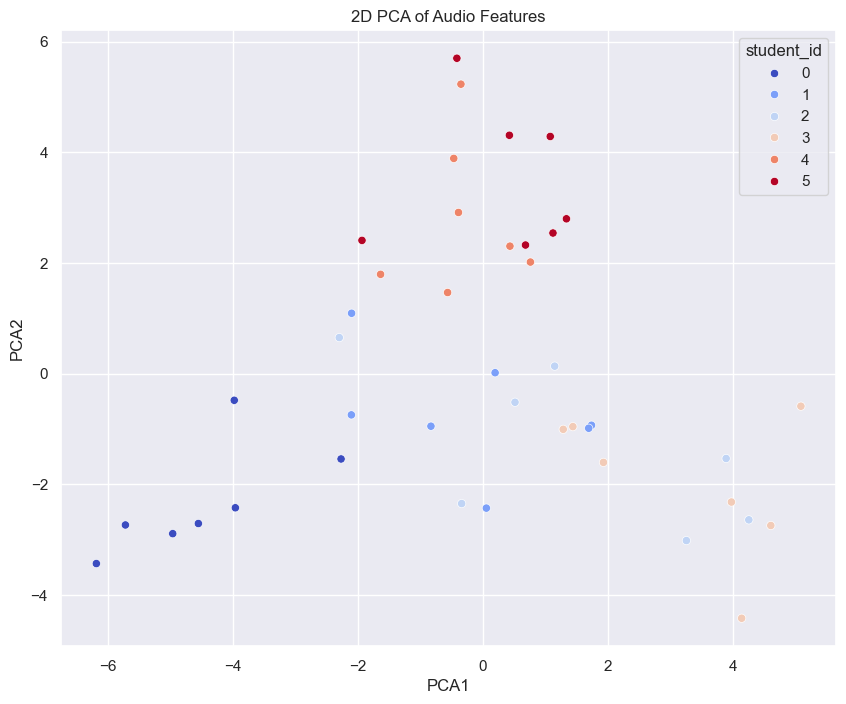

C:\Users\Mr. Hajiheideri\AppData\Local\Temp\ipykernel_15324\2750997229.py:17: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df.drop(columns=['PCA1', 'PCA2'], inplace=True)
C:\Users\Mr. Hajiheideri\AppData\Local\Temp\ipykernel_15324\2750997229.py:20: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['PCA1'] = pca_result[:, 0]
C:\Users\Mr. Hajiheideri\AppData\Local\Temp\ipykernel_15324\2750997229.py:21: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats 

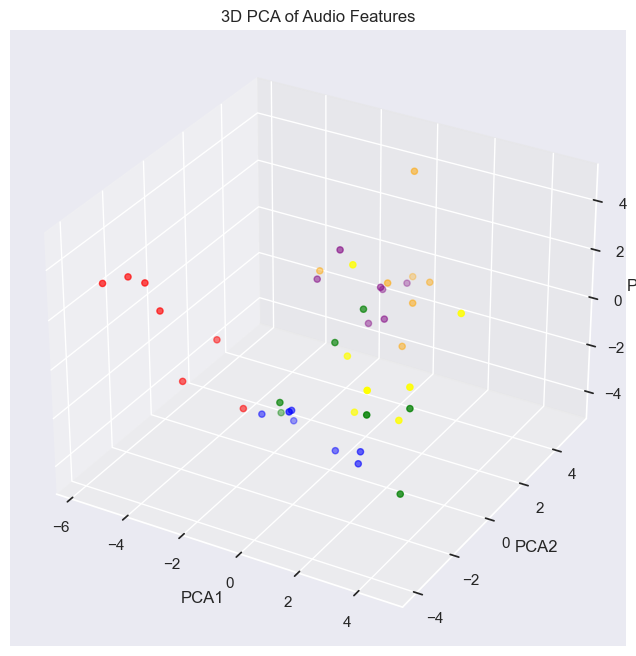

C:\Users\Mr. Hajiheideri\AppData\Local\Temp\ipykernel_15324\2750997229.py:34: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df.drop(columns=['PCA1', 'PCA2', 'PCA3'], inplace=True)


In [ ]:
plot_PCA(data, 'student_id', 2)
plot_PCA(data, 'student_id', 3)

# Normalization

In [116]:
X = data.drop(columns=["student_id"])
y = data["student_id"] 

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=12/42, random_state=42, stratify=y)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [117]:
print(y_test)

504    4
408    4
275    2
464    2
507    5
411    5
619    0
461    1
338    0
646    1
472    3
182    3
Name: student_id, dtype: int32


In [118]:
print(X_train.shape)    
print(X_test.shape)

(30, 31)
(12, 31)


# Model Training

- **MLP** works well if the dataset has non-linear patterns.
- **SVM** is great for small datasets with clear class boundaries.
- **Random Forest** can handle both linear & non-linear relationships.
- **KNN** is useful when data points of the same class are close together.

In [163]:
def train_and_evaluate_models(X_train, X_test, y_train, y_test):

    models = {
        "MLP": MLPClassifier(hidden_layer_sizes=(50, 30), max_iter=500, random_state=42),
        "SVM": SVC(kernel='linear', probability=True, random_state=42),
        "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
        "KNN": KNeighborsClassifier(n_neighbors=3)
    }

    results = {}

    for name, model in models.items():
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        acc = accuracy_score(y_test, y_pred)
        results[name] = acc

        print(f"{name} Accuracy: {acc:.4f}")
        print(classification_report(y_test, y_pred))

        cm = confusion_matrix(y_test, y_pred)
        plt.figure(figsize=(5, 4))
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
        plt.title(f"Confusion Matrix - {name}")
        plt.xlabel("Predicted")
        plt.ylabel("Actual")
        plt.show()


        all_classes = np.unique(y_train)  # Get all possible classes
        y_test_bin = label_binarize(y_test, classes=all_classes)  # Use full class set

        plt.figure(figsize=(8, 6))

        for i, class_label in enumerate(all_classes):
            if hasattr(model, "predict_proba"):
                y_prob = model.predict_proba(X_test)
            else:
                y_prob = model.decision_function(X_test)
                y_prob = (y_prob - y_prob.min()) / (y_prob.max() - y_prob.min())  # Normalize

            if np.sum(y_test_bin[:, i]) == 0:
                print(f"Skipping class {i} as there are no positive samples in the true labels.")
                continue 

            fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_prob[:, i])
            roc_auc = auc(fpr, tpr)
            plt.plot(fpr, tpr, lw=2, label=f"Class {i} (AUC = {roc_auc:.2f})")

        plt.plot([0, 1], [0, 1], color="gray", linestyle="--")
        plt.xlabel("False Positive Rate")
        plt.ylabel("True Positive Rate")
        plt.title("ROC Curve - Multi-Class")
        plt.legend(loc="lower right")
        plt.show()
    
    best_model = max(results, key=results.get)
    print(f"\n Best Model: {best_model} with Accuracy: {results[best_model]:.4f}")

    return results


MLP Accuracy: 1.0000
              precision    recall  f1-score   support

   810100091       1.00      1.00      1.00         2
   810100135       1.00      1.00      1.00         2
   810100150       1.00      1.00      1.00         2
   810100198       1.00      1.00      1.00         2
   810100270       1.00      1.00      1.00         2
   810102142       1.00      1.00      1.00         2

    accuracy                           1.00        12
   macro avg       1.00      1.00      1.00        12
weighted avg       1.00      1.00      1.00        12



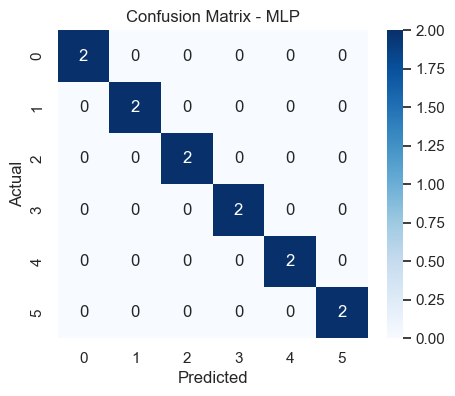

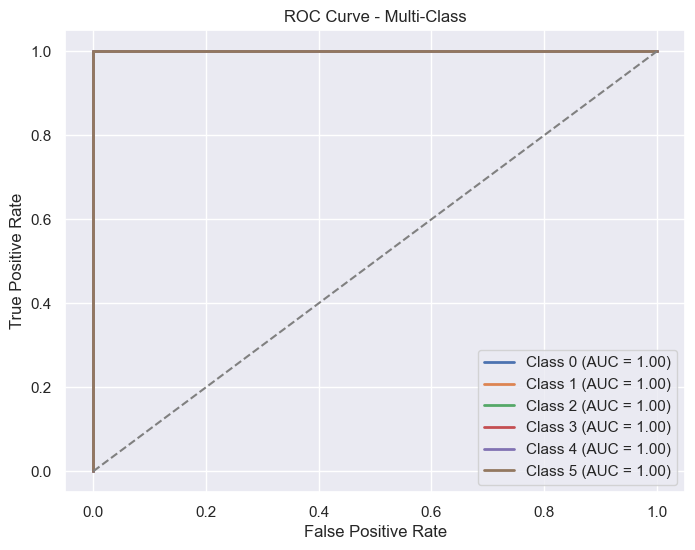

SVM Accuracy: 0.9167
              precision    recall  f1-score   support

   810100091       1.00      1.00      1.00         2
   810100135       1.00      1.00      1.00         2
   810100150       1.00      1.00      1.00         2
   810100198       1.00      0.50      0.67         2
   810100270       0.67      1.00      0.80         2
   810102142       1.00      1.00      1.00         2

    accuracy                           0.92        12
   macro avg       0.94      0.92      0.91        12
weighted avg       0.94      0.92      0.91        12



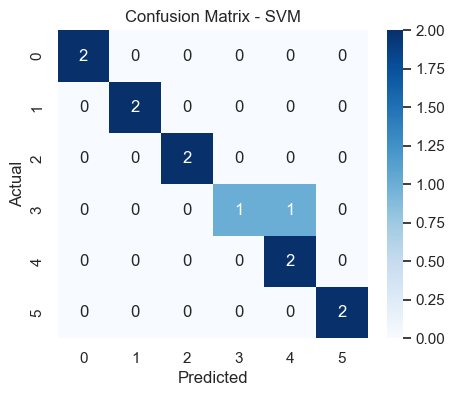

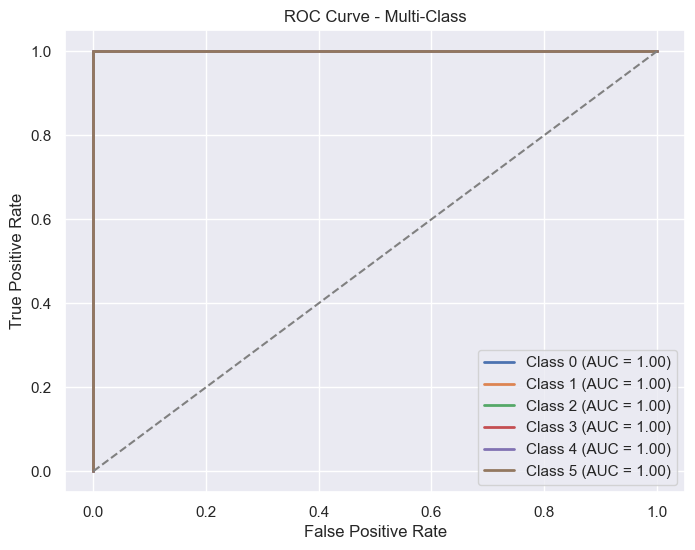

Random Forest Accuracy: 0.9167
              precision    recall  f1-score   support

   810100091       0.67      1.00      0.80         2
   810100135       1.00      1.00      1.00         2
   810100150       1.00      1.00      1.00         2
   810100198       1.00      1.00      1.00         2
   810100270       1.00      1.00      1.00         2
   810102142       1.00      0.50      0.67         2

    accuracy                           0.92        12
   macro avg       0.94      0.92      0.91        12
weighted avg       0.94      0.92      0.91        12



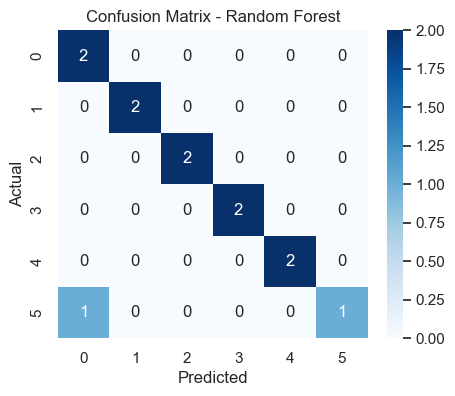

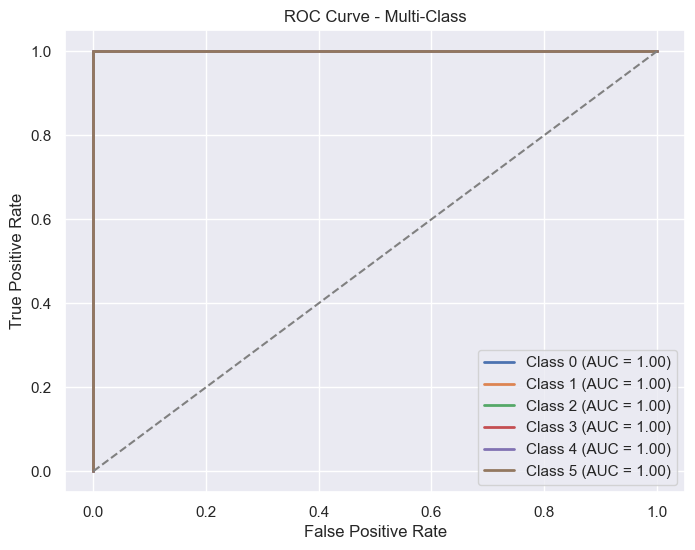

KNN Accuracy: 0.8333
              precision    recall  f1-score   support

   810100091       1.00      1.00      1.00         2
   810100135       1.00      1.00      1.00         2
   810100150       0.67      1.00      0.80         2
   810100198       0.67      1.00      0.80         2
   810100270       1.00      0.50      0.67         2
   810102142       1.00      0.50      0.67         2

    accuracy                           0.83        12
   macro avg       0.89      0.83      0.82        12
weighted avg       0.89      0.83      0.82        12



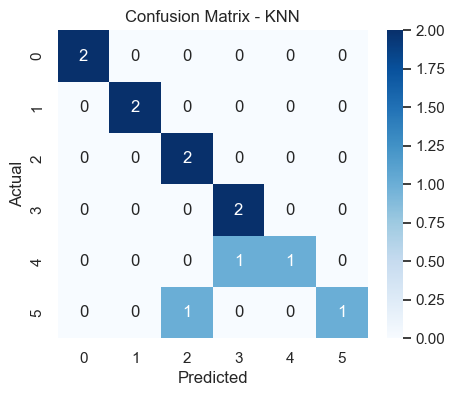

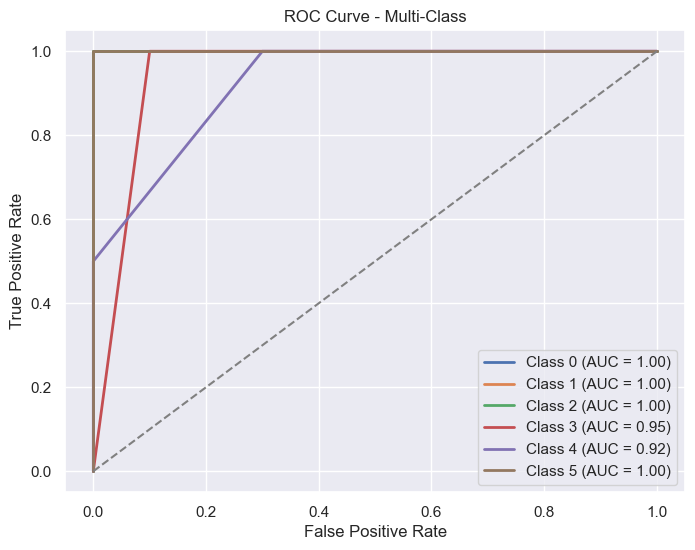


 Best Model: MLP with Accuracy: 1.0000


{'MLP': 1.0,
 'SVM': 0.9166666666666666,
 'Random Forest': 0.9166666666666666,
 'KNN': 0.8333333333333334}

In [164]:
train_and_evaluate_models(X_train, X_test, y_train, y_test)

# Round 2

MLP Accuracy: 0.9167
              precision    recall  f1-score   support

   810100135       1.00      0.50      0.67         2
   810101423       1.00      1.00      1.00         2
   810101575       1.00      1.00      1.00         2
   810103162       0.67      1.00      0.80         2
   810103197       1.00      1.00      1.00         2
   810198500       1.00      1.00      1.00         2

    accuracy                           0.92        12
   macro avg       0.94      0.92      0.91        12
weighted avg       0.94      0.92      0.91        12



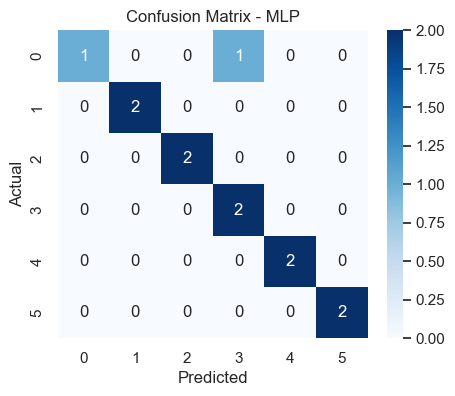

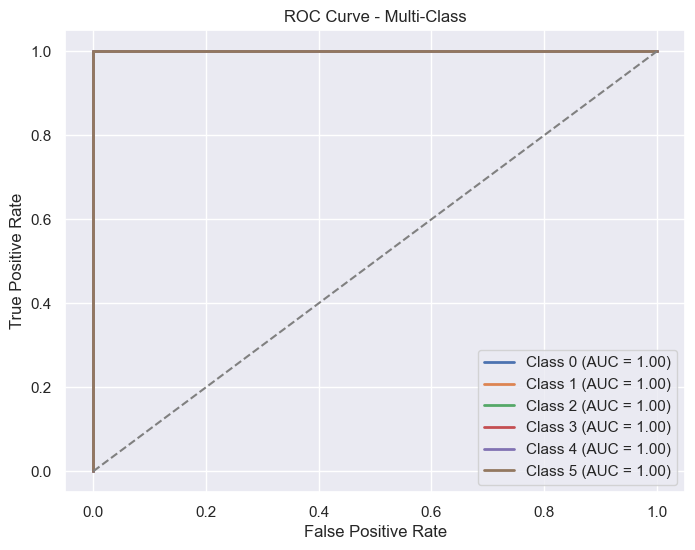

SVM Accuracy: 0.8333
              precision    recall  f1-score   support

   810100135       1.00      0.50      0.67         2
   810101423       0.50      1.00      0.67         2
   810101575       1.00      1.00      1.00         2
   810103162       1.00      0.50      0.67         2
   810103197       1.00      1.00      1.00         2
   810198500       1.00      1.00      1.00         2

    accuracy                           0.83        12
   macro avg       0.92      0.83      0.83        12
weighted avg       0.92      0.83      0.83        12



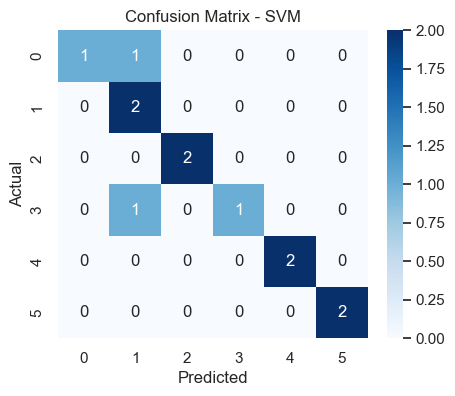

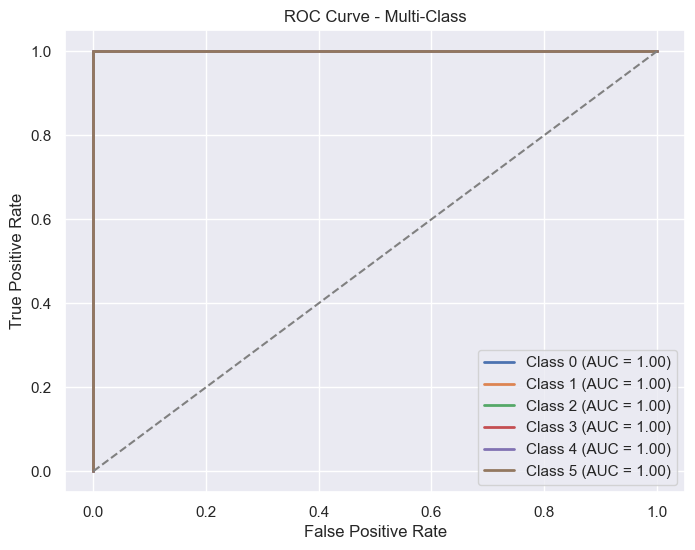

Random Forest Accuracy: 0.9167
              precision    recall  f1-score   support

   810100135       1.00      0.50      0.67         2
   810101423       1.00      1.00      1.00         2
   810101575       1.00      1.00      1.00         2
   810103162       1.00      1.00      1.00         2
   810103197       1.00      1.00      1.00         2
   810198500       0.67      1.00      0.80         2

    accuracy                           0.92        12
   macro avg       0.94      0.92      0.91        12
weighted avg       0.94      0.92      0.91        12



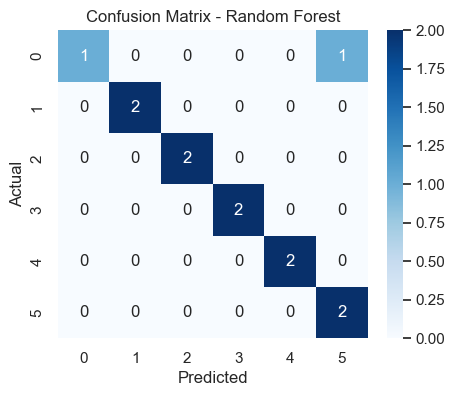

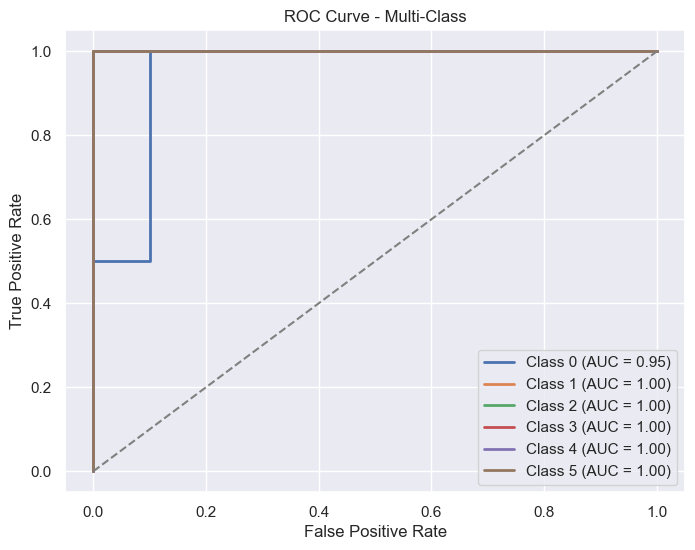

KNN Accuracy: 0.9167
              precision    recall  f1-score   support

   810100135       1.00      1.00      1.00         2
   810101423       0.67      1.00      0.80         2
   810101575       1.00      1.00      1.00         2
   810103162       1.00      0.50      0.67         2
   810103197       1.00      1.00      1.00         2
   810198500       1.00      1.00      1.00         2

    accuracy                           0.92        12
   macro avg       0.94      0.92      0.91        12
weighted avg       0.94      0.92      0.91        12



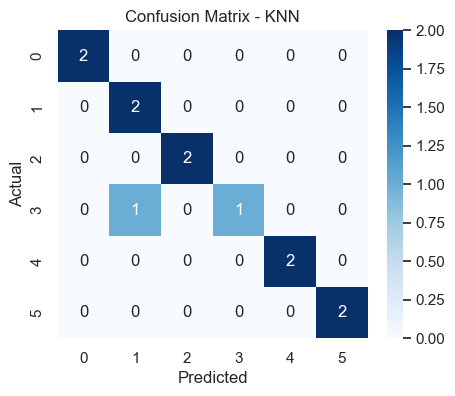

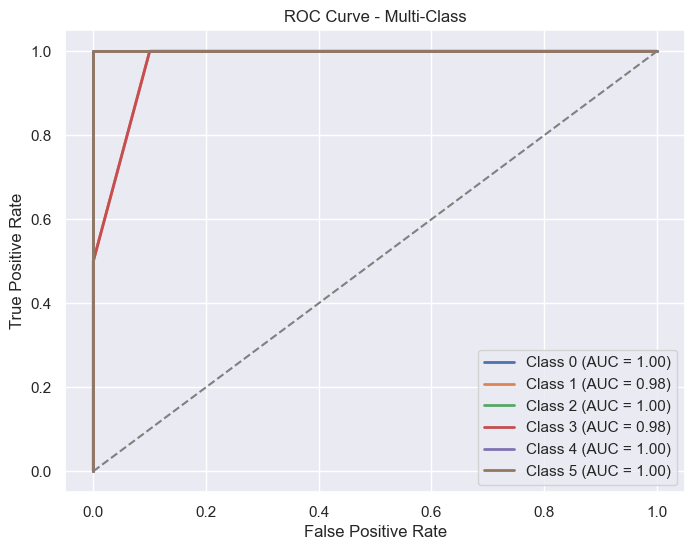


 Best Model: MLP with Accuracy: 0.9167


{'MLP': 0.9166666666666666,
 'SVM': 0.8333333333333334,
 'Random Forest': 0.9166666666666666,
 'KNN': 0.9166666666666666}

In [165]:
data = get_6_students_data()
X = data.drop(columns=["student_id"])
y = data["student_id"] 

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=12/42, random_state=42, stratify=y)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
train_and_evaluate_models(X_train, X_test, y_train, y_test)

# Round 3

MLP Accuracy: 0.9167
              precision    recall  f1-score   support

   810100268       0.67      1.00      0.80         2
   810101413       1.00      1.00      1.00         2
   810102017       1.00      1.00      1.00         2
   810103169       1.00      0.50      0.67         2
   810103322       1.00      1.00      1.00         2
   810199400       1.00      1.00      1.00         2

    accuracy                           0.92        12
   macro avg       0.94      0.92      0.91        12
weighted avg       0.94      0.92      0.91        12



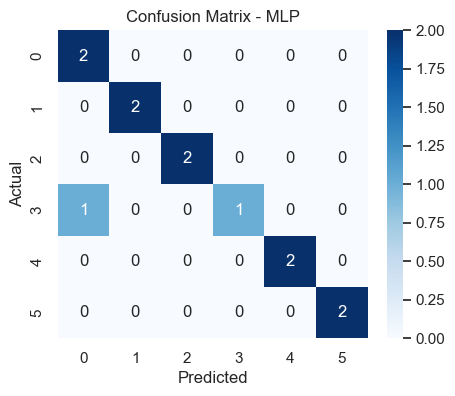

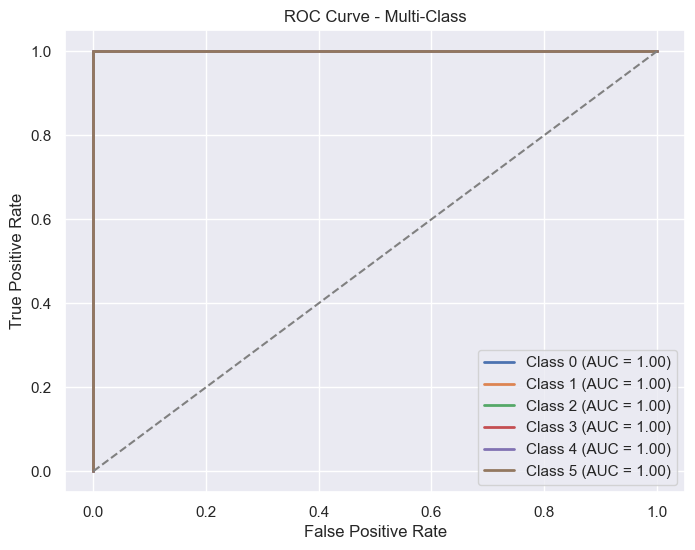

SVM Accuracy: 0.9167
              precision    recall  f1-score   support

   810100268       1.00      1.00      1.00         2
   810101413       1.00      1.00      1.00         2
   810102017       1.00      1.00      1.00         2
   810103169       1.00      0.50      0.67         2
   810103322       0.67      1.00      0.80         2
   810199400       1.00      1.00      1.00         2

    accuracy                           0.92        12
   macro avg       0.94      0.92      0.91        12
weighted avg       0.94      0.92      0.91        12



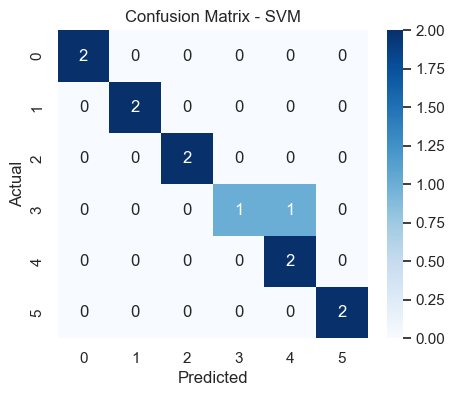

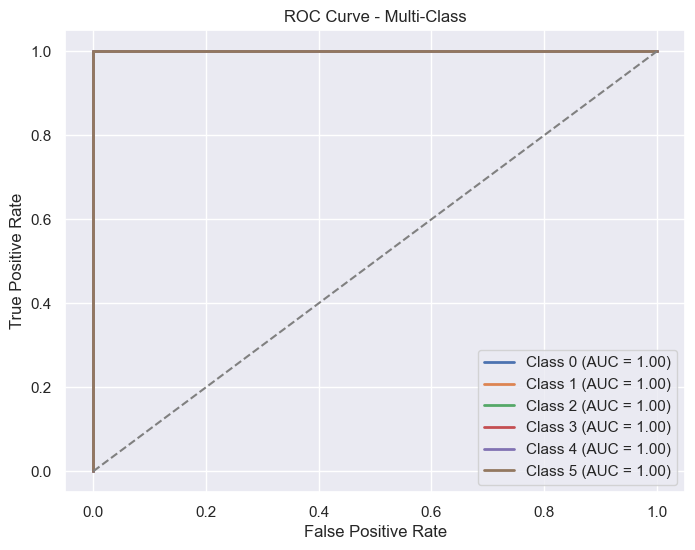

Random Forest Accuracy: 1.0000
              precision    recall  f1-score   support

   810100268       1.00      1.00      1.00         2
   810101413       1.00      1.00      1.00         2
   810102017       1.00      1.00      1.00         2
   810103169       1.00      1.00      1.00         2
   810103322       1.00      1.00      1.00         2
   810199400       1.00      1.00      1.00         2

    accuracy                           1.00        12
   macro avg       1.00      1.00      1.00        12
weighted avg       1.00      1.00      1.00        12



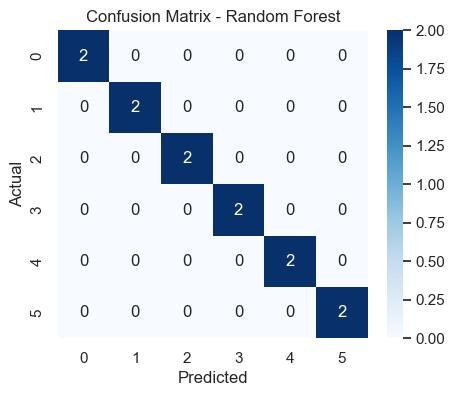

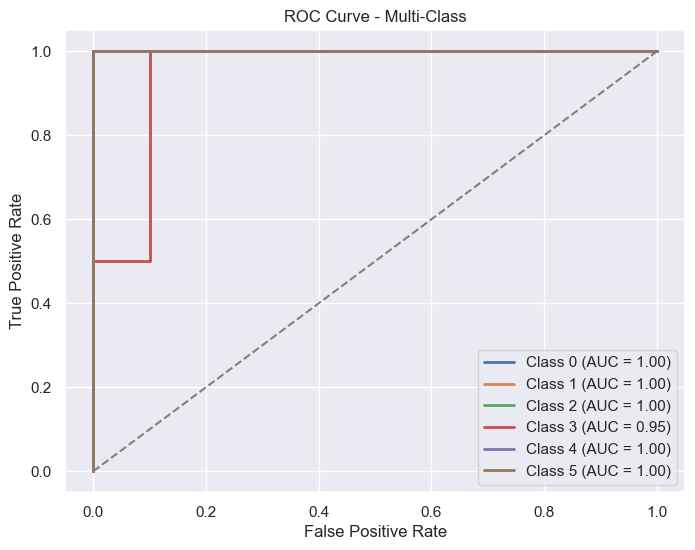

KNN Accuracy: 1.0000
              precision    recall  f1-score   support

   810100268       1.00      1.00      1.00         2
   810101413       1.00      1.00      1.00         2
   810102017       1.00      1.00      1.00         2
   810103169       1.00      1.00      1.00         2
   810103322       1.00      1.00      1.00         2
   810199400       1.00      1.00      1.00         2

    accuracy                           1.00        12
   macro avg       1.00      1.00      1.00        12
weighted avg       1.00      1.00      1.00        12



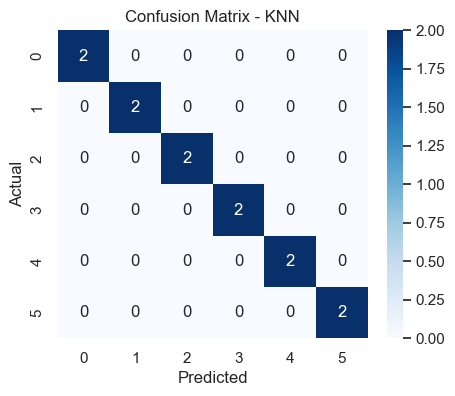

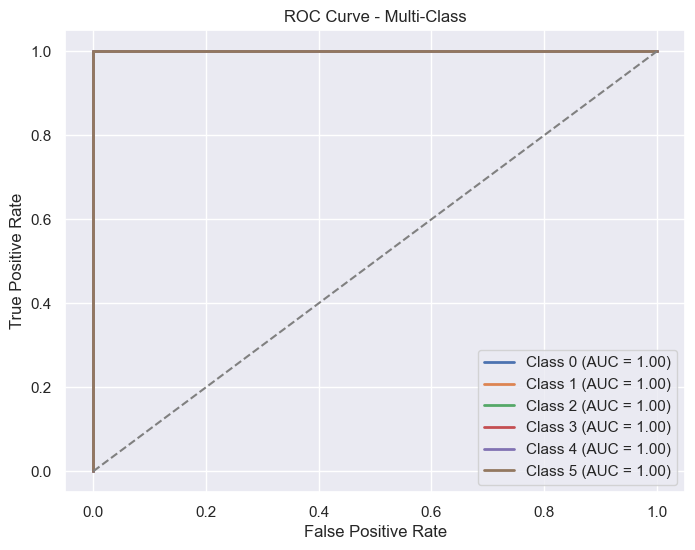


 Best Model: Random Forest with Accuracy: 1.0000


{'MLP': 0.9166666666666666,
 'SVM': 0.9166666666666666,
 'Random Forest': 1.0,
 'KNN': 1.0}

In [166]:
data = get_6_students_data()
X = data.drop(columns=["student_id"])
y = data["student_id"] 

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=12/42, random_state=42, stratify=y)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
train_and_evaluate_models(X_train, X_test, y_train, y_test)